# Module 2: Exploratory Data Analysis (EDA) & Clinical Visualizations
**Project #49:** Stroke Risk Factors & Clinical Triage App  
**Student:** Vaddi Varshitha (`S230617`) | **Course:** Introduction to Data Science (`25A12104`)

---

## Objectives
1. Analyze univariate distributions of continuous (`age`, `avg_glucose_level`, `bmi`) and categorical clinical features.
2. Quantify bivariate stroke prevalence across hypertension, heart disease, smoking status, marital status, work type, and numeric distributions.
3. Examine multivariate correlations and the compounding interaction of age, hypertension, and hyperglycemia on stroke risk.
4. Export publication-ready **300-DPI** figures into `docs/figures/` for the Final Report, Presentation, and Streamlit App.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import CLEANED_EDA_PATH, FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

df = pd.read_csv(CLEANED_EDA_PATH)
print(f"Loaded cleaned EDA dataset: {df.shape}")
df.head()

Loaded cleaned EDA dataset: (5109, 13)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,bmi_was_missing,smoking_was_unknown
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1,0,0
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,29.7,never smoked,1,1,0
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1,0,0
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1,0,0
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1,0,0


## 1. Univariate Analysis: Target Class Imbalance & Numeric Distributions

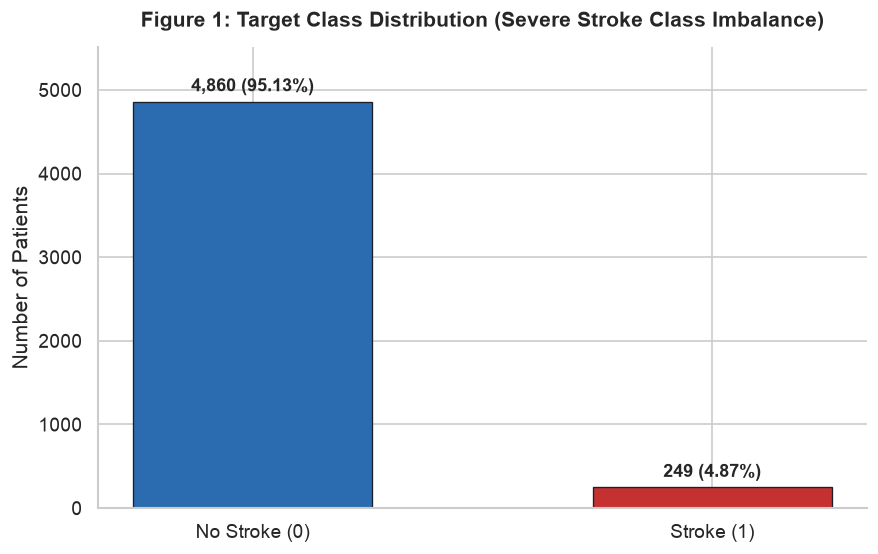

In [2]:
# Figure 1: Target Class Imbalance
fig, ax = plt.subplots(figsize=(7.5, 4.8))
counts = df["stroke"].value_counts().sort_index()
labels = ["No Stroke (0)", "Stroke (1)"]
colors = ["#2b6cb0", "#c53030"]
bars = ax.bar(labels, counts.values, color=colors, width=0.52, edgecolor="#1a202c", linewidth=0.8)

total = len(df)
for bar, cnt in zip(bars, counts.values):
    pct = 100.0 * cnt / total
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + total * 0.015,
        f"{cnt:,} ({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=11,
    )

ax.set_ylim(0, total * 1.08)
ax.set_ylabel("Number of Patients")
ax.set_title("Figure 1: Target Class Distribution (Severe Stroke Class Imbalance)", fontweight="bold", pad=12)
sns.despine(ax=ax)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "01_target_imbalance.png", dpi=300, bbox_inches="tight")
plt.show()

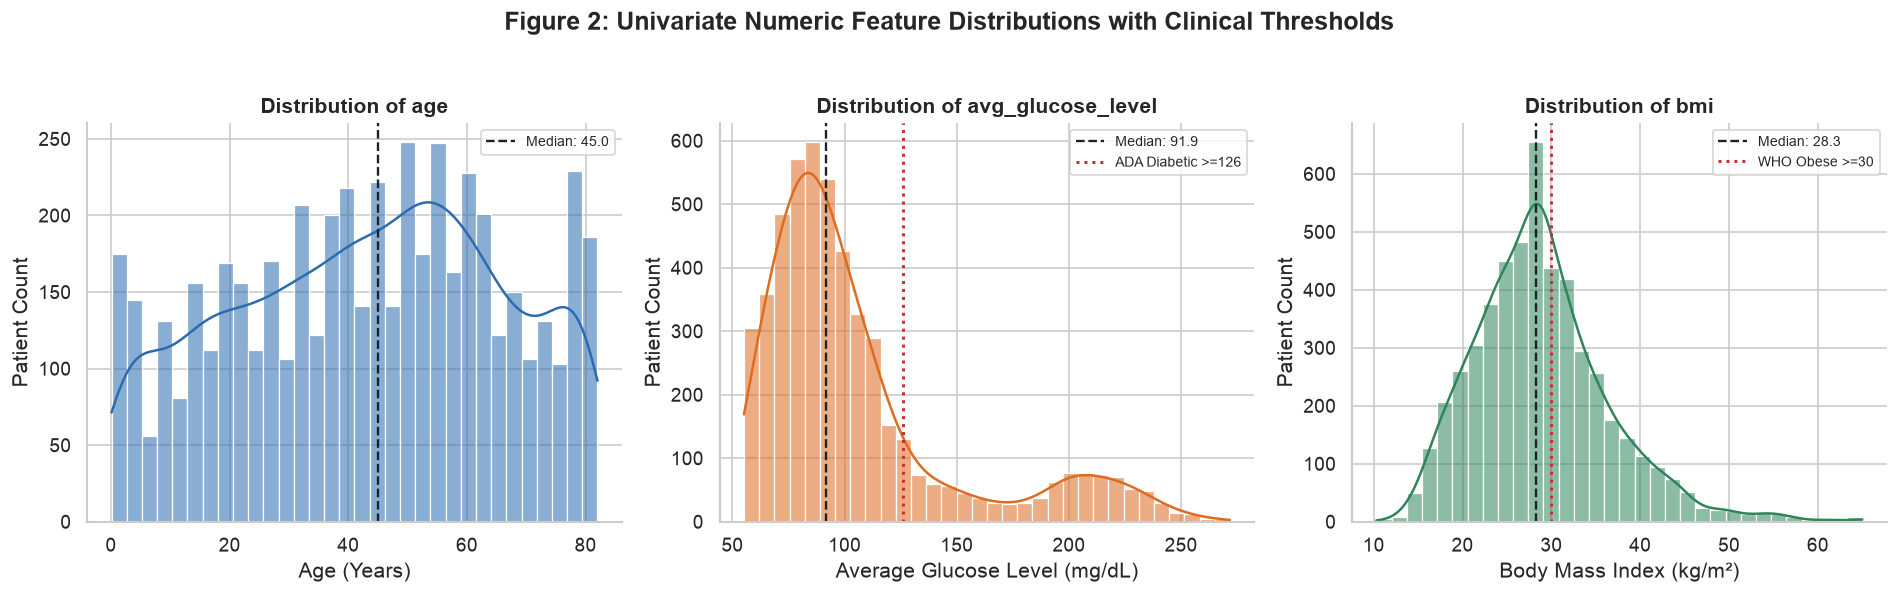

In [3]:
# Figure 2: Numeric Distributions (Age, Avg Glucose Level, BMI)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
specs = [
    ("age", "Age (Years)", "#2b6cb0", None),
    ("avg_glucose_level", "Average Glucose Level (mg/dL)", "#dd6b20", (126.0, "ADA Diabetic >=126")),
    ("bmi", "Body Mass Index (kg/m²)", "#2f855a", (30.0, "WHO Obese >=30")),
]

for ax, (col, xlabel, color, thresh) in zip(axes, specs):
    sns.histplot(df[col], kde=True, bins=32, color=color, alpha=0.55, ax=ax)
    mean_v, med_v = df[col].mean(), df[col].median()
    ax.axvline(med_v, color="#1a202c", linestyle="--", linewidth=1.4, label=f"Median: {med_v:.1f}")
    if thresh is not None:
        ax.axvline(thresh[0], color="#c53030", linestyle=":", linewidth=1.8, label=thresh[1])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Patient Count")
    ax.set_title(f"Distribution of {col}", fontweight="bold")
    ax.legend(fontsize=8.5)
    sns.despine(ax=ax)

fig.suptitle("Figure 2: Univariate Numeric Feature Distributions with Clinical Thresholds", fontweight="bold", y=1.03)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_numeric_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

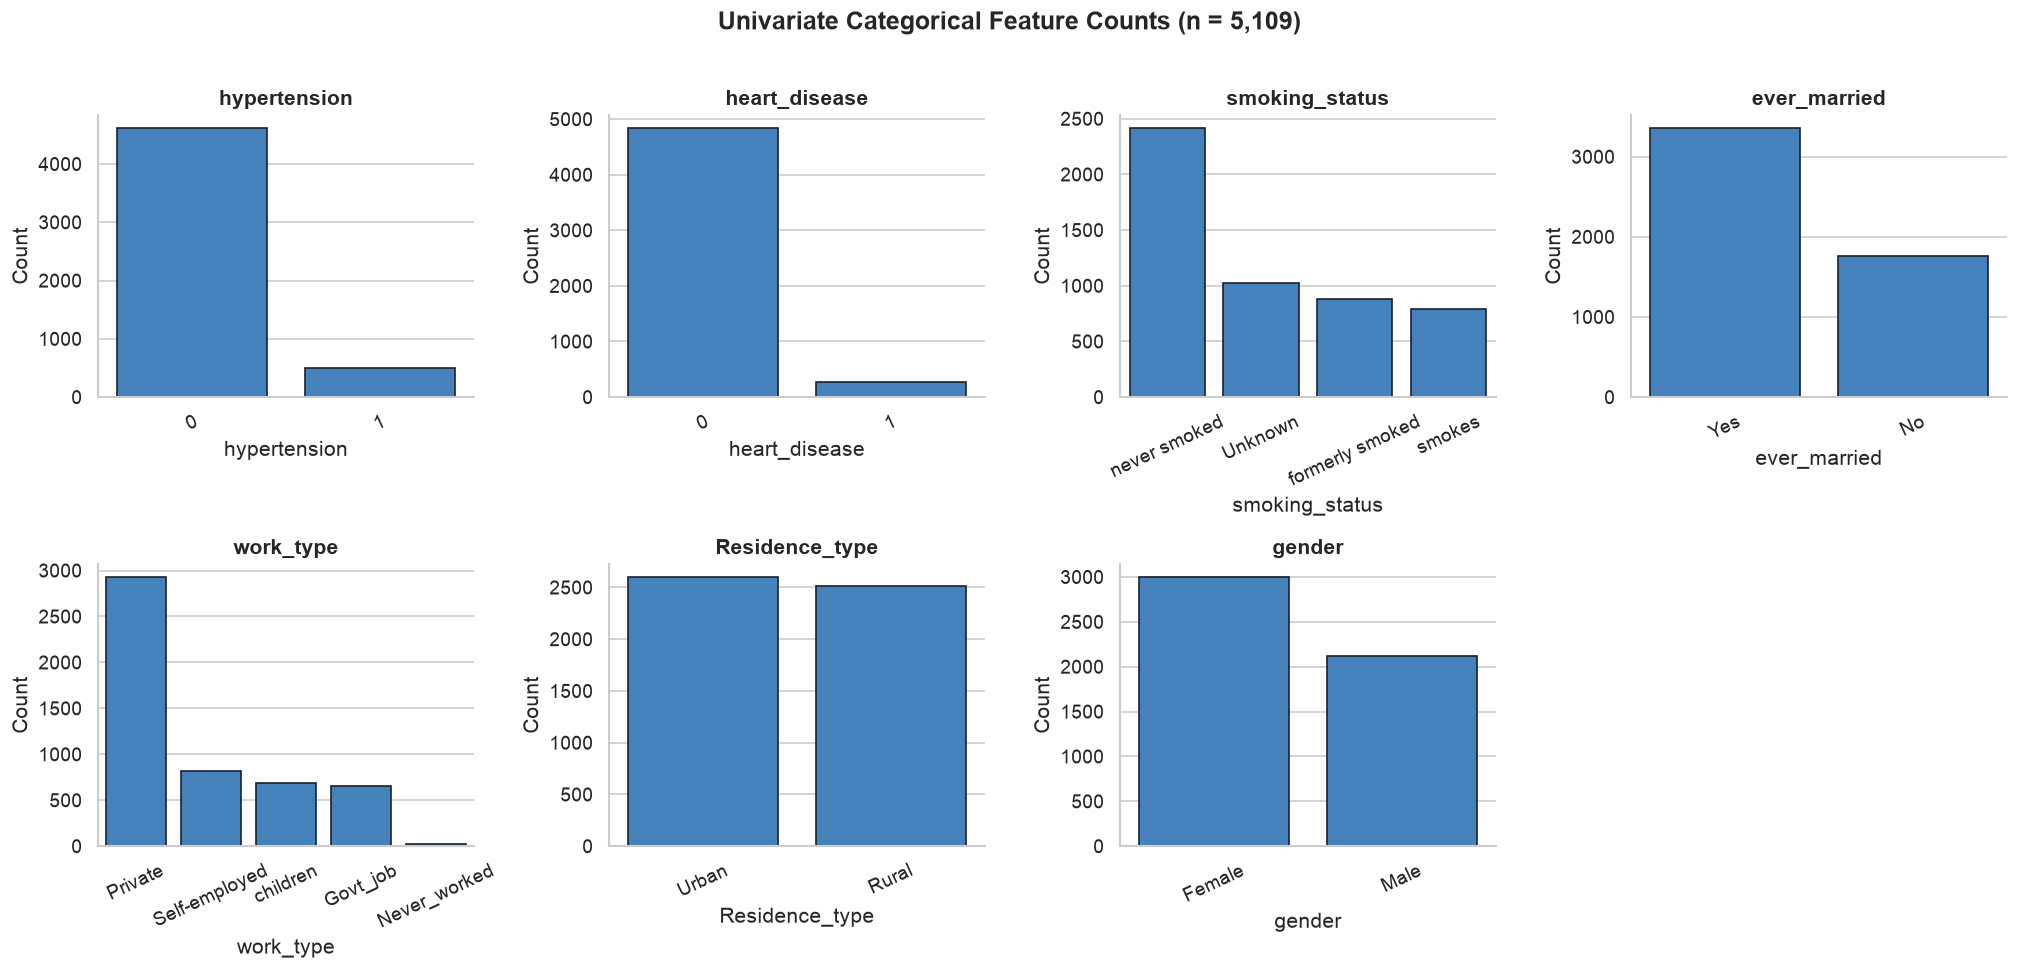

In [4]:
# Univariate Categorical Frequency Summary
cat_cols = ["hypertension", "heart_disease", "smoking_status", "ever_married", "work_type", "Residence_type", "gender"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
axes = axes.flatten()
for idx, col in enumerate(cat_cols):
    vc = df[col].value_counts()
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=axes[idx], color="#3182ce", edgecolor="#1a202c")
    axes[idx].set_title(col, fontweight="bold")
    axes[idx].set_ylabel("Count")
    axes[idx].tick_params(axis="x", rotation=25)
    sns.despine(ax=axes[idx])
axes[-1].axis("off")
fig.suptitle("Univariate Categorical Feature Counts (n = 5,109)", fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Univariate Insights
- **Severe Class Imbalance:** Only **4.87%** (`249 / 5,109`) of patients experienced a stroke. Accuracy is therefore misleading (a naive majority-class model scores 95.1%), motivating imbalance-aware modeling and Recall/PR-AUC evaluation.
- **Bimodal Glucose Distribution:** `avg_glucose_level` displays a clear second mode above **126 mg/dL** (the ADA diabetes threshold), indicating distinct normoglycemic vs. hyperglycemic subpopulations.
- **Right-Skewed BMI:** Median BMI is **28.3 kg/m²** (WHO Overweight range), with a substantial proportion of patients in the Obese (`>=30`) tier.

## 2. Bivariate Analysis: Stroke Prevalence Across Clinical & Demographic Factors

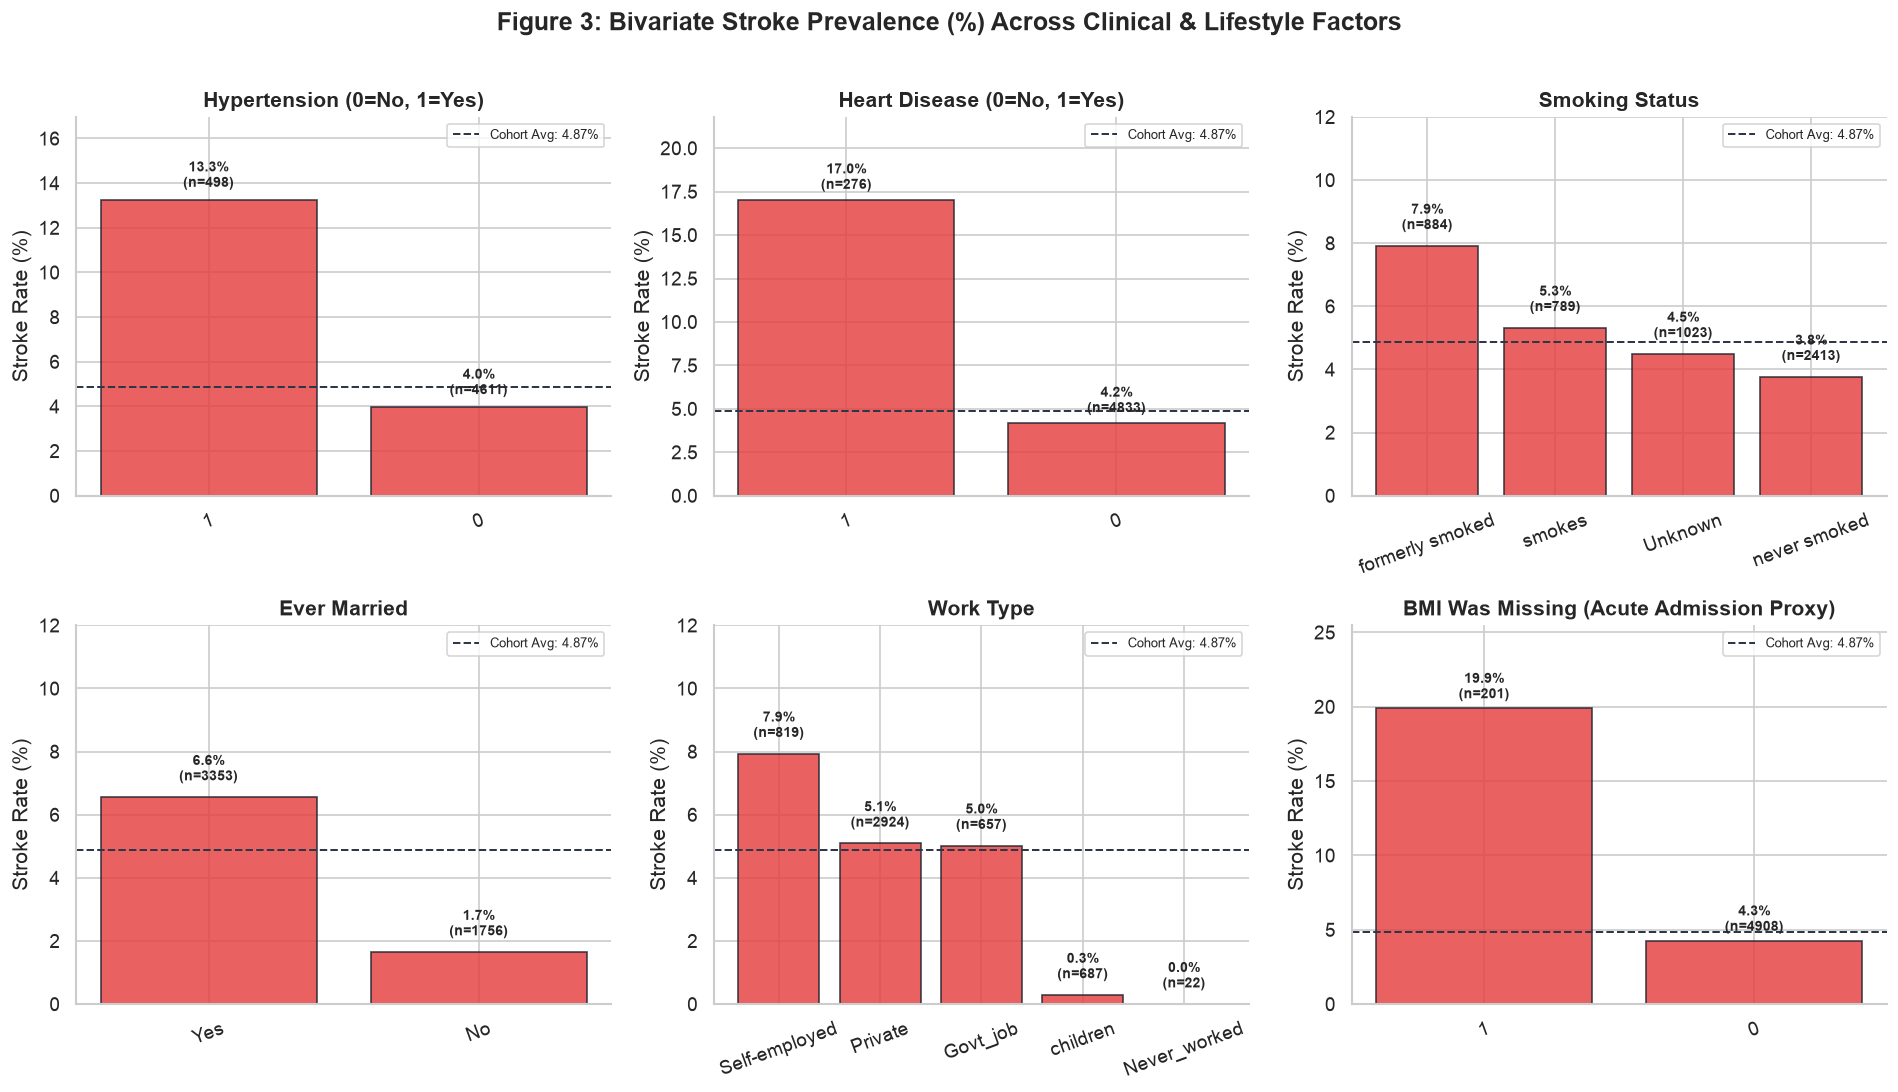

In [5]:
# Figure 3: Stroke Rate (%) Across Key Categorical Risk Factors
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
panels = [
    ("hypertension", "Hypertension (0=No, 1=Yes)"),
    ("heart_disease", "Heart Disease (0=No, 1=Yes)"),
    ("smoking_status", "Smoking Status"),
    ("ever_married", "Ever Married"),
    ("work_type", "Work Type"),
    ("bmi_was_missing", "BMI Was Missing (Acute Admission Proxy)"),
]
baseline_rate = 100.0 * df["stroke"].mean()

for ax, (col, title) in zip(axes, panels):
    summary = df.groupby(col)["stroke"].agg(["count", "mean"]).reset_index()
    summary["rate_pct"] = summary["mean"] * 100.0
    summary = summary.sort_values("rate_pct", ascending=False)
    bars = ax.bar(summary[col].astype(str), summary["rate_pct"], color="#e53e3e", alpha=0.82, edgecolor="#1a202c")
    ax.axhline(baseline_rate, color="#2d3748", linestyle="--", linewidth=1.2, label=f"Cohort Avg: {baseline_rate:.2f}%")
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.4,
            f"{row['rate_pct']:.1f}%\n(n={int(row['count'])})",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
        )
    ax.set_ylim(0, max(summary["rate_pct"].max() * 1.28, 12))
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Stroke Rate (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

fig.suptitle("Figure 3: Bivariate Stroke Prevalence (%) Across Clinical & Lifestyle Factors", fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "03_stroke_rate_by_risk_factors.png", dpi=300, bbox_inches="tight")
plt.show()

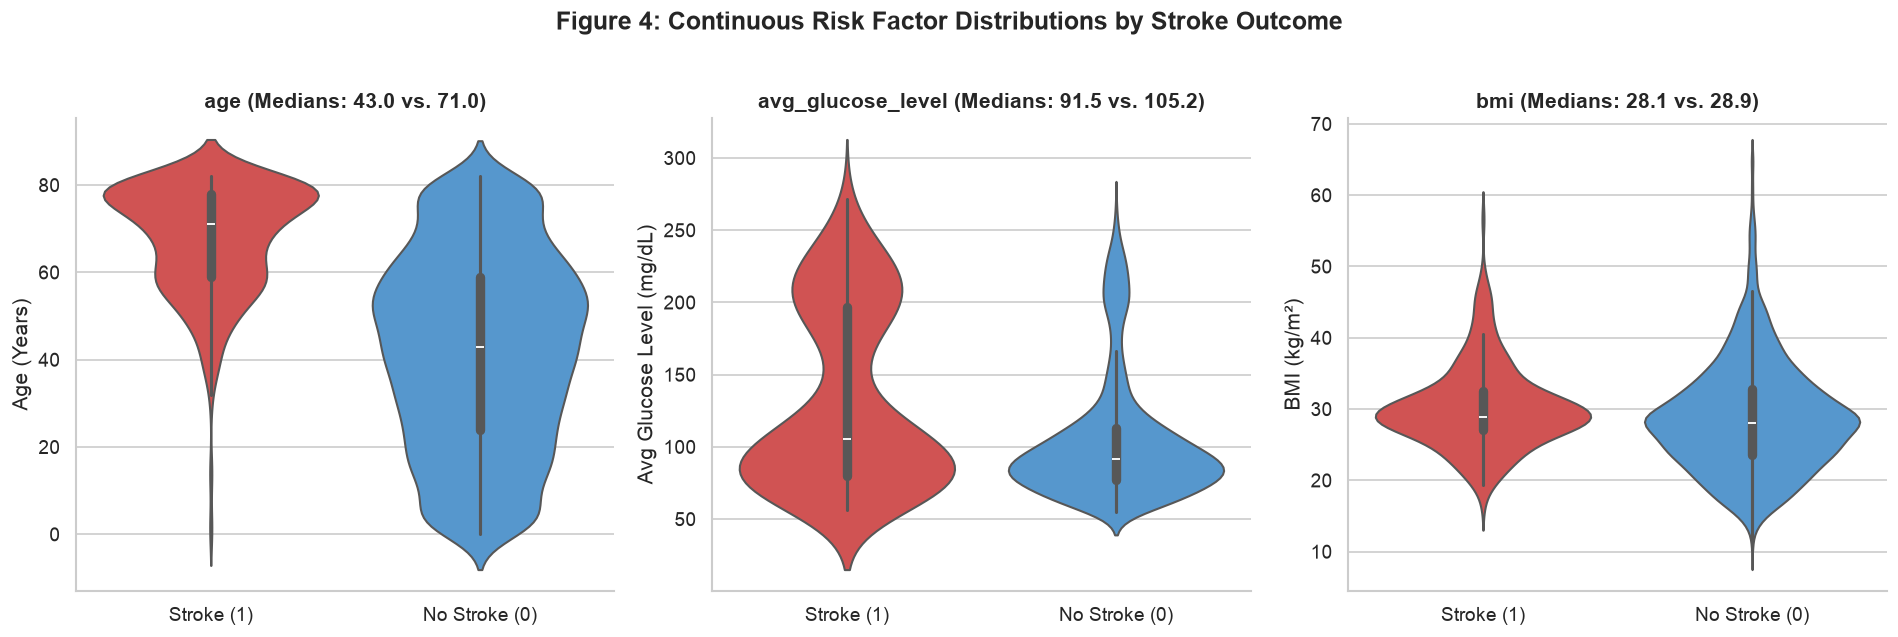

In [6]:
# Figure 4: Age, Avg Glucose Level & BMI by Stroke Outcome
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
plot_df = df.copy()
plot_df["Stroke Outcome"] = plot_df["stroke"].map({0: "No Stroke (0)", 1: "Stroke (1)"})
palette = {"No Stroke (0)": "#4299e1", "Stroke (1)": "#e53e3e"}

for ax, (col, ylabel) in zip(
    axes,
    [("age", "Age (Years)"), ("avg_glucose_level", "Avg Glucose Level (mg/dL)"), ("bmi", "BMI (kg/m²)")],
):
    sns.violinplot(data=plot_df, x="Stroke Outcome", y=col, hue="Stroke Outcome", palette=palette, inner="box", legend=False, ax=ax)
    med0 = df.loc[df["stroke"] == 0, col].median()
    med1 = df.loc[df["stroke"] == 1, col].median()
    ax.set_title(f"{col} (Medians: {med0:.1f} vs. {med1:.1f})", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

fig.suptitle("Figure 4: Continuous Risk Factor Distributions by Stroke Outcome", fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "04_age_glucose_bmi_by_stroke.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Multivariate Analysis: Correlations & Hypertension × Glucose Compounding Risk

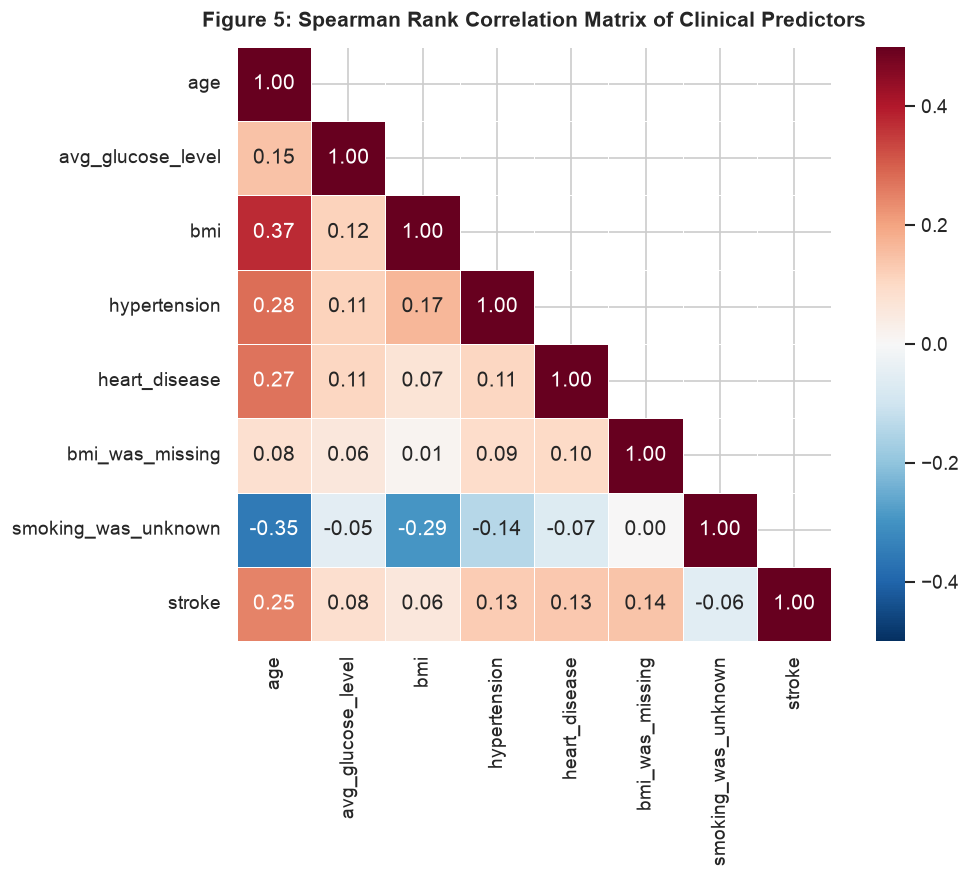

In [7]:
# Figure 5: Spearman Correlation Heatmap
corr_cols = [
    "age", "avg_glucose_level", "bmi", "hypertension",
    "heart_disease", "bmi_was_missing", "smoking_was_unknown", "stroke"
]
corr_mat = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 7.5))
mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(
    corr_mat,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-0.5,
    vmax=0.5,
    square=True,
    linewidths=0.6,
    ax=ax,
)
ax.set_title("Figure 5: Spearman Rank Correlation Matrix of Clinical Predictors", fontweight="bold", pad=12)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

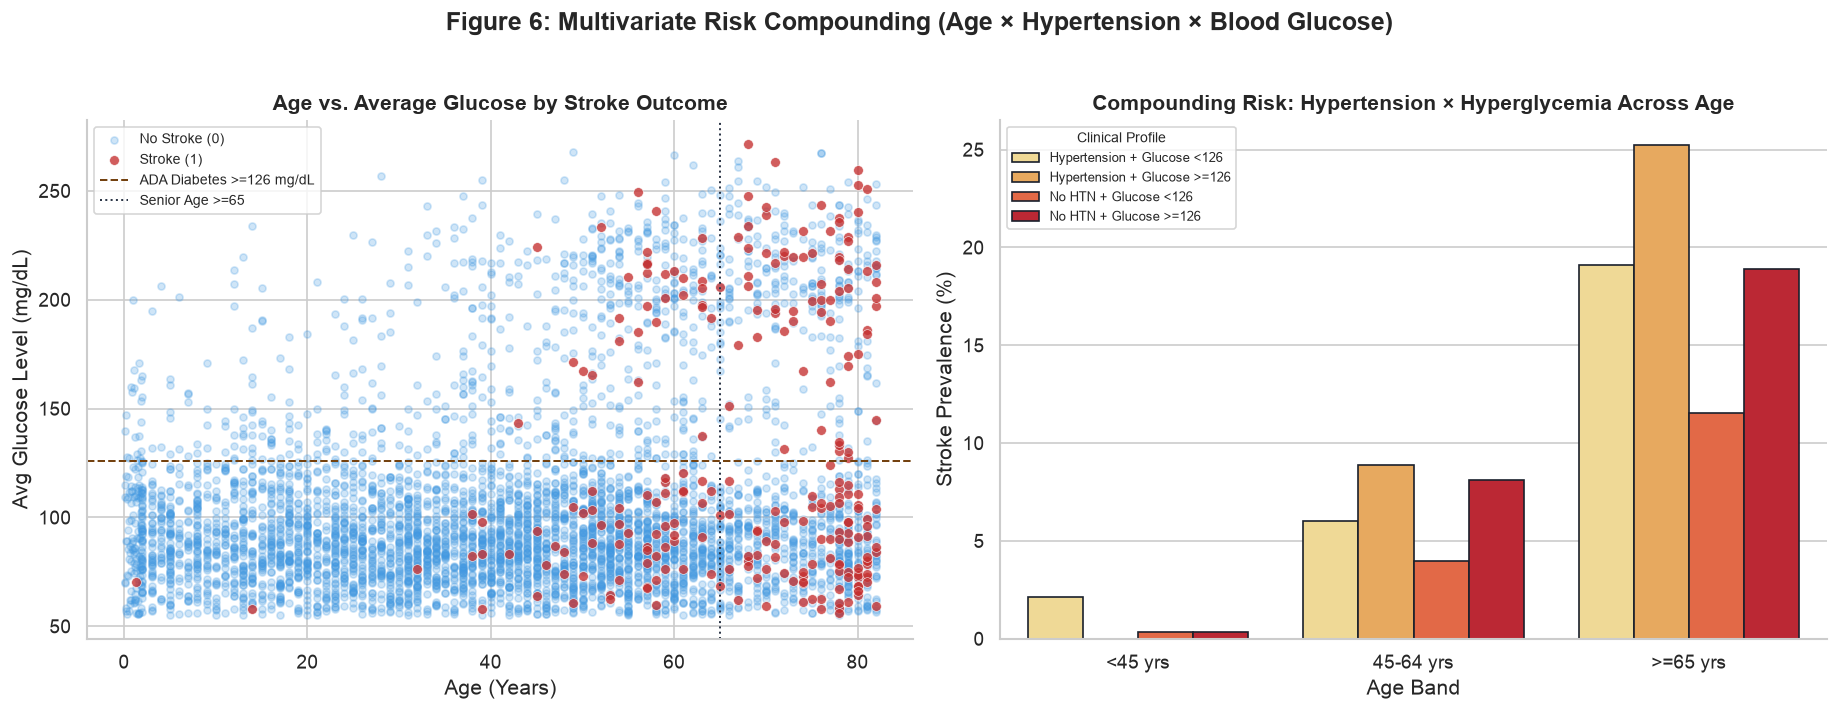

In [8]:
# Figure 6: Multivariate Age vs Glucose Scatter & Hypertension x Glucose Compounding Risk
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8))

# Left panel: Age vs Avg Glucose colored by Stroke
no_stroke = df[df["stroke"] == 0]
yes_stroke = df[df["stroke"] == 1]
axes[0].scatter(no_stroke["age"], no_stroke["avg_glucose_level"], alpha=0.25, s=18, color="#4299e1", label="No Stroke (0)")
axes[0].scatter(yes_stroke["age"], yes_stroke["avg_glucose_level"], alpha=0.78, s=34, color="#c53030", edgecolor="white", linewidth=0.4, label="Stroke (1)")
axes[0].axhline(126.0, color="#744210", linestyle="--", linewidth=1.2, label="ADA Diabetes >=126 mg/dL")
axes[0].axvline(65.0, color="#2d3748", linestyle=":", linewidth=1.2, label="Senior Age >=65")
axes[0].set_xlabel("Age (Years)")
axes[0].set_ylabel("Avg Glucose Level (mg/dL)")
axes[0].set_title("Age vs. Average Glucose by Stroke Outcome", fontweight="bold")
axes[0].legend(fontsize=8.5)
sns.despine(ax=axes[0])

# Right panel: Hypertension x Glucose Tier across Age Bands
tmp = df.copy()
tmp["age_band"] = pd.cut(tmp["age"], bins=[0, 45, 65, 120], labels=["<45 yrs", "45-64 yrs", ">=65 yrs"], right=False)
tmp["high_glucose"] = np.where(tmp["avg_glucose_level"] >= 126.0, "Glucose >=126", "Glucose <126")
tmp["htn_label"] = np.where(tmp["hypertension"] == 1, "Hypertension", "No HTN")
tmp["risk_combo"] = tmp["htn_label"] + " + " + tmp["high_glucose"]

combo_rates = tmp.groupby(["age_band", "risk_combo"], observed=False)["stroke"].mean().mul(100).reset_index()
sns.barplot(data=combo_rates, x="age_band", y="stroke", hue="risk_combo", palette="YlOrRd", edgecolor="#1a202c", ax=axes[1])
axes[1].set_xlabel("Age Band")
axes[1].set_ylabel("Stroke Prevalence (%)")
axes[1].set_title("Compounding Risk: Hypertension × Hyperglycemia Across Age", fontweight="bold")
axes[1].legend(title="Clinical Profile", fontsize=8, title_fontsize=8.5)
sns.despine(ax=axes[1])

fig.suptitle("Figure 6: Multivariate Risk Compounding (Age × Hypertension × Blood Glucose)", fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_hypertension_glucose_interaction.png", dpi=300, bbox_inches="tight")
plt.show()

### Clinical Takeaways from Module 2 EDA
1. **Age is the dominant continuous risk gradient:** Median age among stroke patients is dramatically higher (~71 yrs) compared to non-stroke patients (~43 yrs).
2. **Hypertension & Heart Disease multiply stroke rate:** Both comorbidities exhibit roughly **3×–4× higher unadjusted stroke prevalence** than baseline.
3. **Compounding Cardiometabolic Risk:** Older adults (`>=65`) with both **hypertension** and **hyperglycemia (`>=126 mg/dL`)** represent the highest-prevalence clinical triage cohort.
4. **Ever Married & Work Type Confounding:** Higher unadjusted stroke rates in `ever_married == "Yes"` and `Self-employed` are heavily confounded by age — which we will formally disentangle via **Multivariable Logistic Regression Odds Ratios** in Module 3.